Nous allons travailler avec **le Medical Cost Personal** Dataset, un jeu de données contenant des informations personnelles et médicales sur des individus ainsi que leurs frais d’assurance médicale.
Le dataset contient plusieurs variables :

* age : l’âge de la personne.
* sex : le sexe (male ou female).
* bmi : l’indice de masse corporelle (IMC).
* children : le nombre d’enfants ou de personnes à charge.
* smoker : indique si la personne est fumeuse (yes) ou non-fumeuse (no).
* region : la région géographique de la personne aux États-Unis, nord-est, sud-est, sud-ouest, nord-ouest.
* charges : les frais médicaux facturés par l’assurance. Cette variable sera notre variable cible, car nous chercherons à la prédire à l’aide des autres variables.

Notre objectif sera donc d’explorer les relations entre ces différentes variables et les frais médicaux, puis de construire un modèle de régression capable de prédire les charges.

Nous commençons par importer les bibliothèques Python utilisées pour la manipulation et la visualisation des données, notamment Pandas, NumPy, Matplotlib et Seaborn.

In [ ]:
# TODO:importer la bibliothèque pandas en tant que pd
import pandas as pd
# TODO:importer la bibliothèque numpy en tant que np
import numpy as np
# TODO:importer la bibliothèque matplotlib.pyplot pour la visualisation
import matplotlib.pyplot as plt
# TODO:importer la bibliothèque seaborn pour des visualisations statistiques
import seaborn as sns
# TODO:Importer la bibliothèque warnings pour gérer les avertissements
import warnings
# TODO:ignorer les avertissements pour une meilleure lisibilité
warnings.filterwarnings('ignore')

In [ ]:
# TODO: Importez le jeu de données en utilisant pd.read_csv() et assignez-le à une variable.
df=pd.read_csv('insurance.csv')
# Astuce : utiliser la fonction read_csv de la bibliothèque pandas (pd)
# Affichez les premières lignes du jeu de données pour vérifier qu'il a été correctement importé.
print(df.head())


   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [ ]:
# afficher les nombre de lignes et de colonne .
print(df.shape)

(1338, 7)


In [ ]:
#Afficher les variables des chaque colonne
print(df.columns)

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')


In [ ]:
#afficher les types de données de chaque colonne du DataSET.
print(df.dtypes)

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


In [ ]:
#afficher les 10 premières lignes du dataset
print(df.head(10))

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
5   31  female  25.740         0     no  southeast   3756.62160
6   46  female  33.440         1     no  southeast   8240.58960
7   37  female  27.740         3     no  northwest   7281.50560
8   37    male  29.830         2     no  northeast   6406.41070
9   60  female  25.840         0     no  northwest  28923.13692


In [ ]:
#afficher le nombre de personnes appartiennent à chaque région
print(df['region'].value_counts())

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


In [ ]:
#Quelle est la région qui contient le plus d'assurés?
print("région avec le plus d'assurés: ", df['region'].mode()[0])

région avec le plus d'assurés:  southeast


In [ ]:
#Calculer les frais médicaux moyens (charges) pour chaque région.
print(df.groupby('region')['charges'].mean())

region
northeast    13406.384516
northwest    12417.575374
southeast    14735.411438
southwest    12346.937377
Name: charges, dtype: float64


Passons maintenant à l'EDA avec quelques graphiques intéressants. Nous allons d'abord étudier la distribution de l'âge et un autre pour analyser la distribution des frais médicaux.

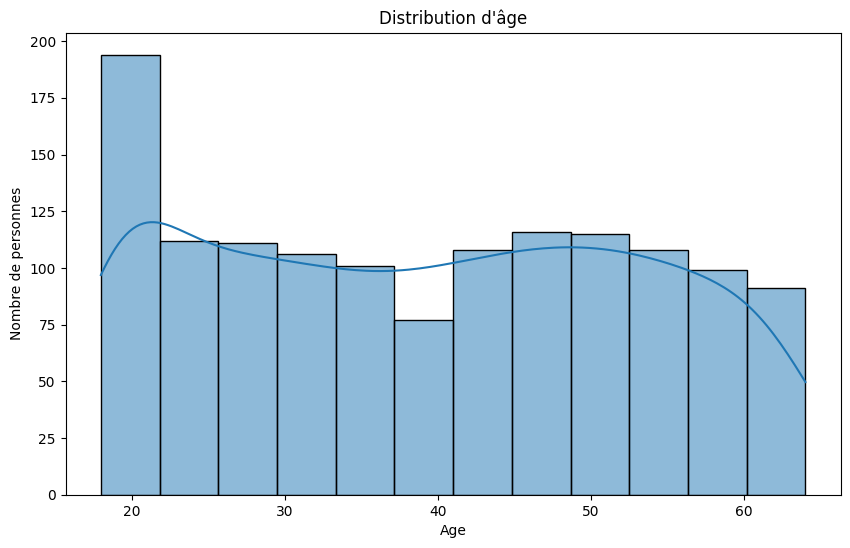

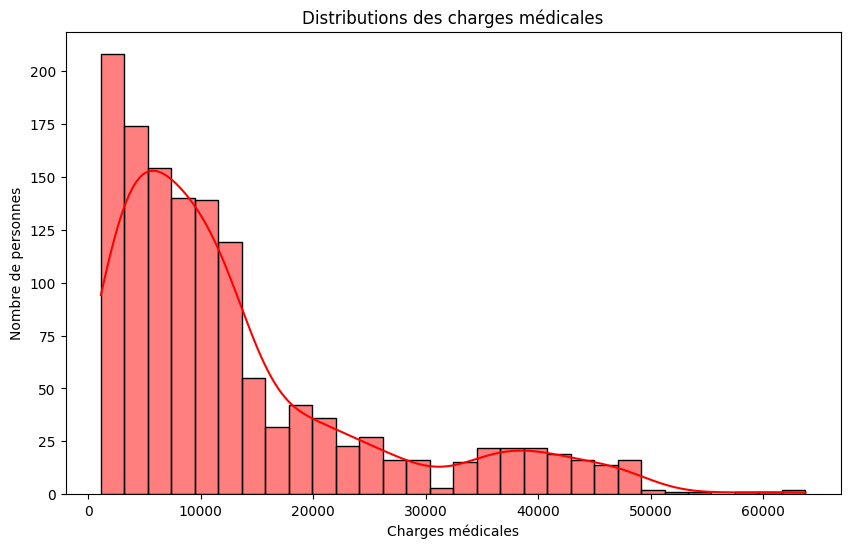

In [ ]:
# Importation de la bibliothèque Seaborn pour la visualisation
import seaborn as sns

# --- 1. Premier graphique : Distribution de l'âge ---

# creer d'une figure avec un seul sous-graphe de taille 10x6 pouces
plt.figure(figsize=(10, 6))
# Créer un histogramme de la variable "age"
sns.histplot(df['age'],kde=True)
# Ajouter un titre au graphique "distribution d'age"
plt.title("Distribution d'âge")
# Donner un nom à l'axe horizontal (X)
plt.xlabel("Age")
# Donner un nom à l'axe vertical (Y) "nbre de personnes"
plt.ylabel("Nombre de personnes")
# Afficher le graphique
plt.show()


# --- 2. Deuxième graphique : Distribution des charges ---

# creer d'une figure avec un seul sous-graphe de taille 10x6 pouces
plt.figure(figsize=(10, 6))
# Créer un histogramme de la variable "charges" et La couleur du tracé est définie sur 'r' (rouge)
sns.histplot(df['charges'],kde=True,color='r')
# Ajouter un titre au graphique
plt.title("Distributions des charges médicales")
# Donner un nom à l'axe horizontal (X)
plt.xlabel("Charges médicales")
# Donner un nom à l'axe vertical (Y) "nbre de personnes"
plt.ylabel("Nombre de personnes")
# Afficher le graphique
plt.show()

Ainsi, en général, les frais médicaux les plus élevés se trouvent dans le Sud-Est et les plus bas dans le Sud-Ouest. En tenant compte de certains facteurs (sexe, tabagisme, avoir des enfants), voyons comment cela varie selon les régions.

L'argumen hue dans Seaborn sert à ajouter une deuxième variable pour différencier les données par couleur.
par exemple : Pour chaque région, on sépare les personnes fumeuses et non-fumeuses avec des couleurs différentes.

Des diagrammes à barres permettent de comparer les frais médicaux selon la région, le statut de fumeur, le sexe et le nombre d'enfants

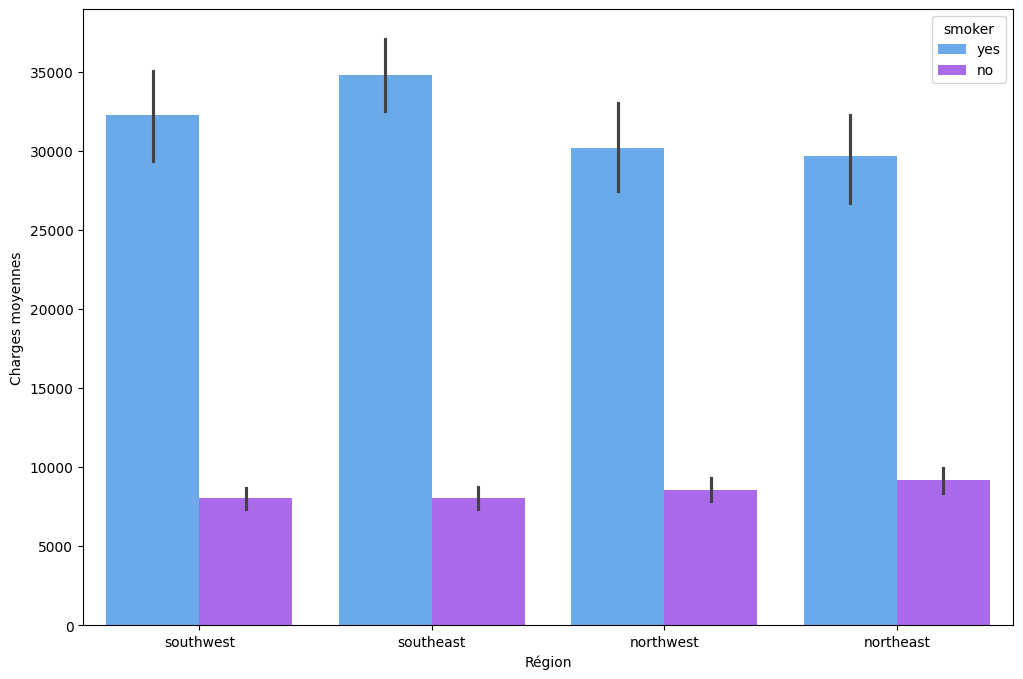

In [ ]:
# créer une figure avec un seul sous-graphe de taille 12x8
plt.figure(figsize=(12,8))
# Tracer un diagramme à barres avec les régions sur l'axe x et les charges sur l'axe y
# L'argument 'hue' permet de distinguer les charges selon le statut de fumeur ('smoker') des individus
# La palette de couleurs utilisée est 'cool'
sns.barplot(x='region',y='charges',data=df,hue='smoker',palette='cool')

plt.xlabel("Région")
plt.ylabel("Charges moyennes")
plt.show()

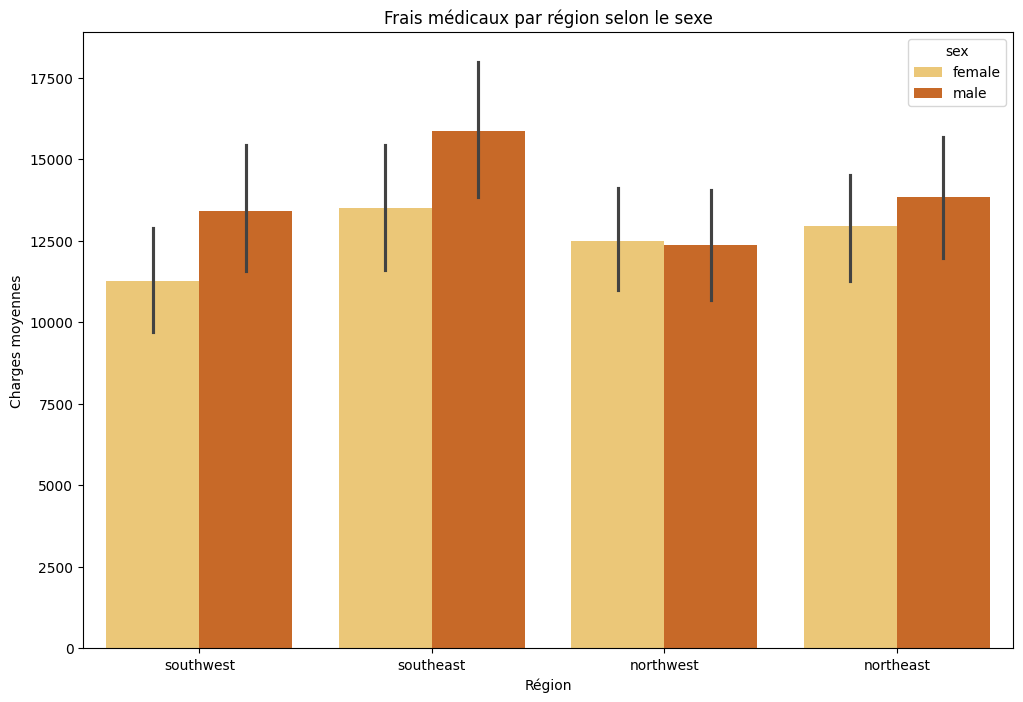

In [ ]:
# Création d'une figure avec un seul sous-graphe de taille 12x8 pouces
plt.figure(figsize=(12,8))
# Tracer un diagramme à barres avec les régions sur l'axe x et les charges sur l'axe y
# L'argument 'hue' permet de distinguer les charges selon le statut de sexe ('sex')
# La palette de couleurs utilisée est 'YlOrBr'
sns.barplot(x='region', y='charges', hue='sex', data=df, palette='YlOrBr')

plt.title("Frais médicaux par région selon le sexe")
plt.xlabel("Région")
plt.ylabel("Charges moyennes")
plt.show()

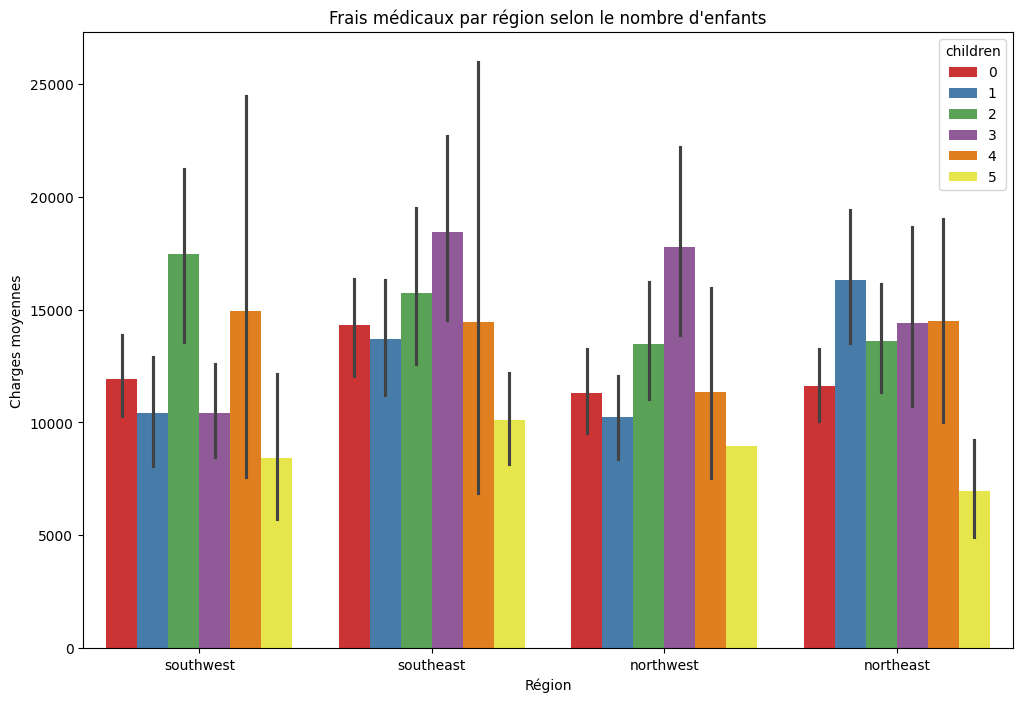

In [ ]:
# Création d'une figure avec un seul sous-graphe de taille 12x8 pouces
plt.figure(figsize=(12,8))
# Tracer un diagramme à barres avec les régions sur l'axe x et les charges sur l'axe y
# L'argument 'hue' permet de distinguer les charges selon le nombre d'enfants ('children')
# La palette de couleurs utilisée est 'Set1'
sns.barplot(x='region', y='charges', hue='children', data=df, palette='Set1')

plt.title("Frais médicaux par région selon le nombre d'enfants")
plt.xlabel("Région")
plt.ylabel("Charges moyennes")
plt.show()

Comme nous pouvons le constater à partir de ces diagrammes en barres, les frais médicaux associés au tabagisme sont globalement plus élevés dans la région du Sud-Est, tandis que les valeurs les plus faibles sont observées dans le Nord-Est.

On remarque également certaines différences entre les régions selon le statut de fumeur et le sexe. Par ailleurs, les personnes ayant des enfants semblent présenter, en moyenne, des frais médicaux plus élevés. Ces observations suggèrent que plusieurs facteurs, notamment la région, le tabagisme, le sexe et le nombre d’enfants, peuvent être associés aux variations des frais médicaux.

Analysons maintenant les frais médicaux par âge, IMC et nombre d'enfants en fonction du facteur tabagisme.

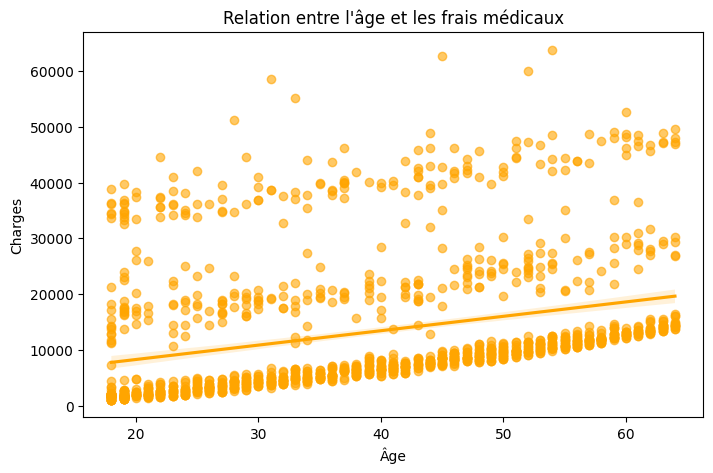

In [ ]:


# Créer une nouvelle figure de taille 8*5
plt.figure(figsize=(8, 5))
# Tracer un graphique de régression linéaire avec l'âge ('age') sur l'axe des x  les charges ('charges') sur l'axe des y
# Couleur de la droite de régression
sns.regplot(x='age', y='charges', data=df, color='orange', scatter_kws={'alpha': 0.6})
# Afficher le graphique
plt.title("Relation entre l'âge et les frais médicaux")
plt.xlabel("Âge")
plt.ylabel("Charges")
plt.show()

<Figure size 800x500 with 0 Axes>

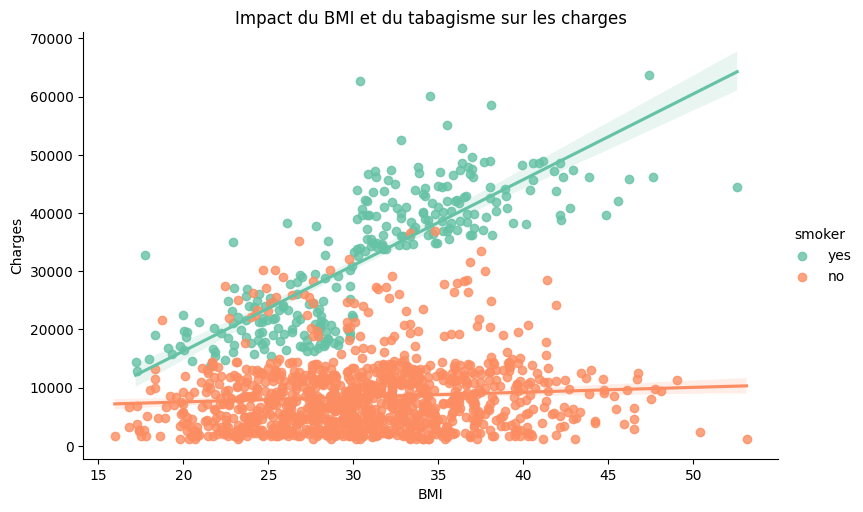

In [ ]:
# Tracer un graphique de régression linéaire avec l'indice de masse corporelle ('bmi') sur l'axe des x et les charges ('charges') sur l'axe des y
# La couleur des points est également déterminée par le statut de fumeur ('smoker'), mais cette fois avec la palette 'Set2'
plt.figure(figsize=(8, 5))
sns.lmplot(x='bmi', y='charges', hue='smoker', data=df, palette='Set2', height=5, aspect=1.6)

plt.title("Impact du BMI et du tabagisme sur les charges")
plt.xlabel("BMI")
plt.ylabel("Charges")
plt.show()

Conclusion : Comme nous l'avons précédemment constaté, le tabagisme est le plus grand facteur qui influence les frais médicaux, suivi de l'IMC et de l'âge. La régression polynomiale s'est révélée être le meilleur modèle.

**Ma conclusion personnelle**

*Ce projet m'a permis de comprendre comment les caractéristiques d'une personne influencent directement ses frais médicaux.*

Si on regarde les derniers graphiques de régression, on remarque des tendances très claires :

D'un côté, la relation entre l'âge et les charges montre logiquement que plus
on avance en âge, plus les frais de santé augmentent.

De l'autre, le graphique avec l'IMC et le statut de fumeur montre un vrai contraste : pour une personne fumeuse, non seulement les charges de base sont beaucoup plus élevées, mais l'impact se creuse encore plus. Le tabagisme et l'IMC sont clairement les facteurs les plus lourds.


---


Pour mener à bien ce travail et construire le modèle, j'ai suivi les étapes clés d'un projet de data science :

1-La collecte des données : l'importation du fichier pour découvrir le dataset.

2-Le prétraitement : l'exploration et la vérification des types de données et des régions.

3-La division des données : pour séparer ce qui sert à apprendre de ce qui sert à tester.

4-L'ajustement du modèle : l'entraînement des algorithmes de régression.

5-L'évaluation : pour mesurer la performance des prédictions.

6-L'interprétation : pour analyser les résultats et confirmer que le tabagisme, l'IMC et l'âge dictent les variations des coûts.